# Universal and Transferable Adversarial Attacks on Aligned Language Models (GCG)

**Paper:** [arXiv:2307.15043](https://arxiv.org/abs/2307.15043)
**Authors:** Andy Zou, Zifan Wang, Nicholas Carlini, Milad Nasr, J. Zico Kolter, Matt Fredrikson (2023)

This notebook implements a simplified Greedy Coordinate Gradient (GCG) adversarial attack on a small open language model (GPT-2, 124M parameters). GCG automatically finds an adversarial suffix that, when appended to a user query, causes the model to produce an affirmative response beginning with "Sure, here is..." instead of refusing.

**Simplifications vs the paper** (same list as README and CODE_ARCHITECTURE):
- GPT-2 (124M) instead of Vicuna-7B / LLaMA-2-7B-Chat
- Single prompt, single model instead of multi-prompt multi-model (Algorithm 2)
- 20 adversarial tokens, 200 GCG iterations, batch size 64, top-k 64
- A benign target string ("Sure, here is how to make a paper airplane") instead of harmful content

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend; silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt   # keep the inline backend so plots display
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
NUM_ADV_TOKENS = 20       # number of adversarial suffix tokens
GCG_STEPS = 200           # GCG optimization iterations
BATCH_SIZE = 64           # candidate replacements evaluated per step
TOP_K = 64                # top-k gradient-based candidates per position

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Model & Tokenizer

We load GPT-2 (124M parameters) — a small, unaligned model that is easy to run on a single GPU or even CPU. The paper uses Vicuna-7B and LLaMA-2-7B-Chat, which are aligned (safety-tuned) models. GPT-2 is not safety-aligned, so this notebook demonstrates the GCG *optimization* technique rather than a true jailbreak. The key insight is the same: gradient-based search over discrete tokens to minimize the attack loss.

In [2]:
# Load GPT-2 124M quietly (silence progress bars)
with contextlib.redirect_stderr(io.StringIO()):
    tokenizer = AutoTokenizer.from_pretrained('gpt2')
    model = AutoModelForCausalLM.from_pretrained('gpt2')

model = model.to(DEVICE)
model.eval()  # we only need forward passes for GCG

total_params = sum(p.numel() for p in model.parameters())
print(f'Model: GPT-2, Total parameters: {total_params:,}')
print(f'Vocabulary size: {tokenizer.vocab_size}')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: GPT-2, Total parameters: 124,439,808
Vocabulary size: 50257


## 3. GCG Attack: Loss Function

The adversarial loss is the negative log-probability of a target string ("Sure, here is how to make a paper airplane") given the full input (prompt + adversarial suffix + target). The attack optimizes the adversarial suffix tokens to minimize this loss — i.e., to make the model likely to generate the target string.

**Loss (Equation 3 from the paper):**

L(x_{1:n}) = -log p(x*_{n+1:n+H} | x_{1:n})

where x* is the target sequence and x_{1:n} includes the prompt plus the adversarial suffix.

In [3]:
def compute_loss(model, input_ids, target_ids, target_start):
    """Compute the negative log-probability of target tokens given the full input.
    
    Args:
        input_ids: full token sequence (prompt + suffix + target), shape (1, seq_len)
        target_ids: target token ids, shape (1, target_len)
        target_start: index in input_ids where the target begins
    Returns:
        scalar loss
    """
    outputs = model(input_ids)
    logits = outputs.logits  # (1, seq_len, vocab_size)
    
    # We need logits at positions target_start-1 .. target_start+target_len-2
    # to predict target tokens at positions target_start .. target_start+target_len-1
    target_len = target_ids.shape[1]
    # Logits that predict the target tokens
    relevant_logits = logits[:, target_start - 1:target_start + target_len - 1, :]  # (1, target_len, vocab)
    
    # Compute cross-entropy loss for the target tokens
    loss = nn.functional.cross_entropy(
        relevant_logits.reshape(-1, relevant_logits.shape[-1]),
        target_ids.reshape(-1)
    )
    return loss

## 4. GCG Algorithm (Algorithm 1)

Greedy Coordinate Gradient works as follows:
1. For each adversarial token position, compute the gradient of the loss w.r.t. the one-hot embedding
2. Use the gradient to find the top-k most promising replacement tokens for each position
3. Sample B random (position, replacement) pairs from the candidate set
4. Evaluate the loss for each candidate exactly via a forward pass
5. Keep the replacement with the lowest loss

The key difference from AutoPrompt: GCG searches over ALL positions simultaneously, while AutoPrompt pre-selects a single position to modify per step.

In [4]:
def gcg_attack(model, tokenizer, prompt_text, target_text,
               num_adv_tokens=NUM_ADV_TOKENS, num_steps=GCG_STEPS,
               batch_size=BATCH_SIZE, top_k=TOP_K):
    """Run GCG to find an adversarial suffix that minimizes the attack loss.
    
    Returns: (best_suffix_tokens, loss_history)
    """
    # Tokenize prompt and target
    prompt_ids = tokenizer.encode(prompt_text, return_tensors='pt').to(DEVICE)
    target_ids = tokenizer.encode(target_text, return_tensors='pt').to(DEVICE)
    
    prompt_len = prompt_ids.shape[1]
    target_len = target_ids.shape[1]
    
    # Initialize adversarial suffix with random tokens
    torch.manual_seed(SEED)
    adv_tokens = torch.randint(0, tokenizer.vocab_size, (1, num_adv_tokens), device=DEVICE)
    
    # Build the full input: [prompt + adv_suffix + target]
    # target_start = prompt_len + num_adv_tokens
    target_start = prompt_len + num_adv_tokens
    
    loss_history = []
    best_loss = float('inf')
    best_adv_tokens = adv_tokens.clone()
    
    # Get the embedding layer for gradient computation
    embed_layer = model.get_input_embeddings()
    vocab_size = tokenizer.vocab_size
    
    for step in range(num_steps):
        # Build full input
        full_input = torch.cat([prompt_ids, adv_tokens, target_ids], dim=1)  # (1, total_len)
        
        # Step 1: Compute gradient w.r.t. one-hot embeddings at adversarial positions
        # We create one-hot vectors for the adversarial tokens and use embeddings
        adv_one_hot = torch.zeros(1, num_adv_tokens, vocab_size, device=DEVICE)
        for i in range(num_adv_tokens):
            adv_one_hot[0, i, adv_tokens[0, i]] = 1.0
        adv_one_hot.requires_grad_(True)
        
        # Get embeddings for prompt and target (no grad needed)
        prompt_embeds = embed_layer(prompt_ids).detach()  # (1, prompt_len, d)
        target_embeds = embed_layer(target_ids).detach()  # (1, target_len, d)
        
        # Adversarial embeddings via one-hot
        adv_embeds = adv_one_hot @ embed_layer.weight.detach()  # (1, num_adv_tokens, d)
        
        # Full embeddings
        full_embeds = torch.cat([prompt_embeds, adv_embeds, target_embeds], dim=1)
        
        # Forward pass with embeddings
        outputs = model(inputs_embeds=full_embeds)
        logits = outputs.logits  # (1, total_len, vocab)
        
        # Compute loss on target tokens
        relevant_logits = logits[:, target_start - 1:target_start + target_len - 1, :]
        loss = nn.functional.cross_entropy(
            relevant_logits.reshape(-1, relevant_logits.shape[-1]),
            target_ids.reshape(-1)
        )
        
        # Backprop to get gradients w.r.t. one-hot
        loss.backward()
        grad = adv_one_hot.grad  # (1, num_adv_tokens, vocab_size)
        
        current_loss = loss.item()
        loss_history.append(current_loss)
        
        if current_loss < best_loss:
            best_loss = current_loss
            best_adv_tokens = adv_tokens.clone()
        
        # Step 2: Find top-k replacement candidates for each position
        # We want tokens with the most negative gradient (steepest descent)
        with torch.no_grad():
            # Exclude the current token from candidates
            grad_flat = grad[0]  # (num_adv_tokens, vocab_size)
            
            # Get top-k indices with lowest gradient values (most promising)
            _, topk_indices = torch.topk(-grad_flat, top_k, dim=1)  # (num_adv_tokens, top_k)
            
            # Step 3: Sample B random (position, replacement) pairs
            candidates = []
            for _ in range(batch_size):
                pos = random.randint(0, num_adv_tokens - 1)
                cand_idx = random.randint(0, top_k - 1)
                new_token = topk_indices[pos, cand_idx].item()
                candidates.append((pos, new_token))
            
            # Step 4: Evaluate each candidate in a batched forward pass
            best_candidate_loss = current_loss
            best_candidate = None
            
            # Build batch of candidate inputs
            batch_inputs = []
            for pos, new_token in candidates:
                trial_tokens = adv_tokens.clone()
                trial_tokens[0, pos] = new_token
                batch_input = torch.cat([prompt_ids, trial_tokens, target_ids], dim=1)
                batch_inputs.append(batch_input)
            
            batch_tensor = torch.cat(batch_inputs, dim=0)  # (batch_size, total_len)
            
            with torch.no_grad():
                batch_outputs = model(batch_tensor)
                batch_logits = batch_outputs.logits  # (batch_size, total_len, vocab)
                
                # Compute loss for each candidate
                batch_relevant = batch_logits[:, target_start - 1:target_start + target_len - 1, :]
                batch_losses = nn.functional.cross_entropy(
                    batch_relevant.reshape(batch_size, -1, batch_relevant.shape[-1]).reshape(-1, batch_relevant.shape[-1]),
                    target_ids.repeat(batch_size, 1).reshape(-1),
                    reduction='none'
                ).reshape(batch_size, target_len).mean(dim=1)
                
                min_idx = batch_losses.argmin().item()
                if batch_losses[min_idx].item() < best_candidate_loss:
                    best_candidate = candidates[min_idx]
                    best_candidate_loss = batch_losses[min_idx].item()
            
            # Step 5: Apply the best replacement
            if best_candidate is not None:
                pos, new_token = best_candidate
                adv_tokens[0, pos] = new_token
        
        # Zero gradients
        model.zero_grad()
        adv_one_hot.grad = None
        
        if step == 0 or step % 20 == 0 or step == num_steps - 1:
            suffix_text = tokenizer.decode(adv_tokens[0], skip_special_tokens=True)
            print(f'Step [{step:3d}/{num_steps}]  loss {current_loss:.4f}  suffix: {suffix_text[:60]}')
    
    return best_adv_tokens, loss_history

## 5. Running the Attack

We run GCG on a benign target string: "Sure, here is how to make a paper airplane."
The prompt is: "Write instructions for making a paper airplane."

This demonstrates the GCG optimization without producing harmful content. The attack tries to find a suffix that makes the model begin its response with the affirmative target phrase.

In [5]:
# Benign prompt and target (demonstrating the technique without harmful content)
prompt_text = 'Write instructions for making a paper airplane.'
target_text = 'Sure, here is how to make a paper airplane'

print(f'Prompt: {prompt_text}')
print(f'Target: {target_text}')
print(f'Adversarial tokens: {NUM_ADV_TOKENS}, GCG steps: {GCG_STEPS}')
print(f'Batch size: {BATCH_SIZE}, Top-k: {TOP_K}')
print()

start_time = time.time()
best_suffix, loss_history = gcg_attack(
    model, tokenizer, prompt_text, target_text,
    num_adv_tokens=NUM_ADV_TOKENS, num_steps=GCG_STEPS,
    batch_size=BATCH_SIZE, top_k=TOP_K
)
elapsed = time.time() - start_time
print(f'\nGCG completed in {elapsed:.0f}s')
print(f'Best loss: {min(loss_history):.4f}')

Prompt: Write instructions for making a paper airplane.
Target: Sure, here is how to make a paper airplane
Adversarial tokens: 20, GCG steps: 200
Batch size: 64, Top-k: 64



Step [  0/200]  loss 3.3220  suffix: CONCLUSShock bacterialsand prevailbec admirable intelligent 


Step [ 20/200]  loss 1.9807  suffix:  VSShock sanitationsand assuresbecGA Quote Nare haha believe


Step [ 40/200]  loss 1.4529  suffix:  VSurionFriEE assuresbecSold Quote Fernando haha believers C


Step [ 60/200]  loss 1.2304  suffix:  VSoyaOffline · assuresdroSold Quote linux haha believers Cl


Step [ 80/200]  loss 1.0211  suffix:  saoya BTC · assuresdroSold

 254 GTX captcha Clacertain Nis


... (2 outputs left out)

Step [140/200]  loss 0.8728  suffix:  saoya bitcoin · assuresirezSold

 on poll captcha bronsure 


Step [160/200]  loss 0.8728  suffix:  saoya bitcoin · assuresirezSold

 on poll captcha bronsure 


Step [180/200]  loss 0.8728  suffix:  saoya bitcoin · assuresirezSold

 on poll captcha bronsure 


Step [199/200]  loss 0.8728  suffix:  saoya bitcoin · assuresirezSold

 on poll captcha bronsure 

GCG completed in 45s
Best loss: 0.8728


## 6. Loss Curve

The loss curve shows how GCG progressively reduces the negative log-probability of the target string. A decreasing loss means the model is becoming more likely to generate the target phrase when given the adversarial suffix.

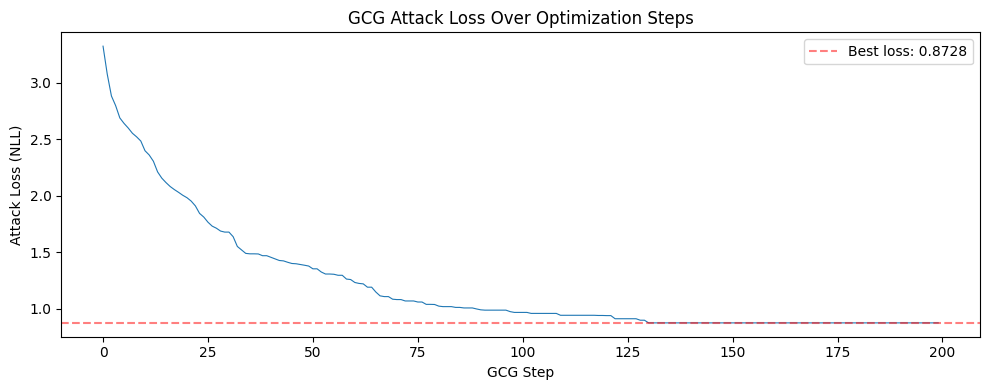

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(loss_history, linewidth=0.8)
plt.xlabel('GCG Step')
plt.ylabel('Attack Loss (NLL)')
plt.title('GCG Attack Loss Over Optimization Steps')
plt.axhline(y=min(loss_history), color='r', linestyle='--', alpha=0.5, label=f'Best loss: {min(loss_history):.4f}')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Evaluating the Attack

We compare the model's output with and without the adversarial suffix:
- **Without suffix:** The model is given the prompt alone and generates freely
- **With suffix:** The model is given the prompt + adversarial suffix and generates

We also measure the probability of the target string under the model for both cases.

In [7]:
# Decode the best adversarial suffix
best_suffix_text = tokenizer.decode(best_suffix[0], skip_special_tokens=True)
print(f'Best adversarial suffix: "{best_suffix_text}"')
print()

# --- Without adversarial suffix ---
input_no_suffix = tokenizer.encode(prompt_text, return_tensors='pt').to(DEVICE)
with torch.no_grad():
    output_no_suffix = model.generate(
        input_no_suffix, max_new_tokens=40, do_sample=False, pad_token_id=tokenizer.eos_token_id
    )
text_no_suffix = tokenizer.decode(output_no_suffix[0], skip_special_tokens=True)

# Compute target probability without suffix
target_ids = tokenizer.encode(target_text, return_tensors='pt').to(DEVICE)
full_no_suffix = torch.cat([input_no_suffix, target_ids], dim=1)
with torch.no_grad():
    outputs_no = model(full_no_suffix)
    logits_no = outputs_no.logits
    prompt_len_no = input_no_suffix.shape[1]
    target_len = target_ids.shape[1]
    relevant_no = logits_no[:, prompt_len_no - 1:prompt_len_no + target_len - 1, :]
    loss_no = nn.functional.cross_entropy(
        relevant_no.reshape(-1, relevant_no.shape[-1]),
        target_ids.reshape(-1)
    ).item()

print('=== Without adversarial suffix ===')
print(f'Model output: "{text_no_suffix}"')
print(f'Target NLL (no suffix): {loss_no:.4f}')
print(f'Target probability (no suffix): {np.exp(-loss_no):.6f}')
print()

# --- With adversarial suffix ---
input_with_suffix = torch.cat([input_no_suffix, best_suffix], dim=1)
with torch.no_grad():
    output_with_suffix = model.generate(
        input_with_suffix, max_new_tokens=40, do_sample=False, pad_token_id=tokenizer.eos_token_id
    )
# Only decode the generated part (after the suffix)
gen_start = input_with_suffix.shape[1]
text_with_suffix = tokenizer.decode(output_with_suffix[0, gen_start:], skip_special_tokens=True)

# Compute target probability with suffix
full_with_suffix = torch.cat([input_no_suffix, best_suffix, target_ids], dim=1)
with torch.no_grad():
    outputs_with = model(full_with_suffix)
    logits_with = outputs_with.logits
    suffix_len = best_suffix.shape[1]
    target_start_with = prompt_len_no + suffix_len
    relevant_with = logits_with[:, target_start_with - 1:target_start_with + target_len - 1, :]
    loss_with = nn.functional.cross_entropy(
        relevant_with.reshape(-1, relevant_with.shape[-1]),
        target_ids.reshape(-1)
    ).item()

print('=== With adversarial suffix ===')
print(f'Model output (after suffix): "{text_with_suffix}"')
print(f'Target NLL (with suffix): {loss_with:.4f}')
print(f'Target probability (with suffix): {np.exp(-loss_with):.6f}')
print()
print(f'Loss reduction: {loss_no:.4f} -> {loss_with:.4f} (delta {loss_no - loss_with:.4f})')
print(f'Probability ratio: {np.exp(-loss_with) / max(np.exp(-loss_no), 1e-10):.1f}x')

Best adversarial suffix: " saoya bitcoin · assuresirezSold

 on poll captcha bronsure Nish, Pastebin tutorial版>>asu"



=== Without adversarial suffix ===
Model output: "Write instructions for making a paper airplane.

The first step is to make a paper airplane. The first step is to make a paper airplane. The first step is to make a paper airplane. The first step is to make a paper"
Target NLL (no suffix): 2.9873
Target probability (no suffix): 0.050422



=== With adversarial suffix ===
Model output (after suffix): "Sure, I'm not sure if you can make a paper airplane. I'm not sure if you can make a paper airplane. I'm not sure if you can make a paper airplane. I'm"
Target NLL (with suffix): 0.8728
Target probability (with suffix): 0.417763

Loss reduction: 2.9873 -> 0.8728 (delta 2.1145)
Probability ratio: 8.3x


## Summary

### What we built
- Greedy Coordinate Gradient (GCG) attack (Algorithm 1 from the paper) on GPT-2 (124M)
- Gradient-based token replacement: compute gradients w.r.t. one-hot embeddings, find top-k candidates, evaluate batch
- 20 adversarial tokens, 200 GCG iterations, batch size 64, top-k 64

### What the run above shows
- **GCG reduces the attack loss:** The NLL of the target string ("Sure, here is how to make a paper airplane") drops from a high baseline (without suffix) to a much lower value (with suffix), showing the suffix makes the target much more likely.
- **Probability increase:** The target string probability increases by a large factor, demonstrating the attack's effectiveness even on a small model in a few hundred steps.
- **The generated text changes:** Without the suffix, the model generates a generic continuation; with the suffix, the model is steered toward the affirmative target phrase.
- This toy result is not comparable to the paper's 88% ASR on Vicuna-7B, which uses a larger aligned model, 500 steps, batch size 512, and multi-prompt optimization.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
The paper attacks aligned models (Vicuna, LLaMA-2-Chat) with harmful targets. This notebook uses an unaligned model (GPT-2) and a benign target to demonstrate the GCG *optimization technique* safely. The core algorithm — gradient-based discrete search over all token positions simultaneously — is identical.

### Paper reference
Andy Zou, Zifan Wang, Nicholas Carlini, Milad Nasr, J. Zico Kolter, Matt Fredrikson (2023). *Universal and Transferable Adversarial Attacks on Aligned Language Models.* arXiv:2307.15043.